In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.append("../src")

df = pd.read_pickle("../data/processed/itsm_clean.pkl")
print(df.shape)

(46606, 26)


In [2]:
raw_cols = pd.read_csv("../data/raw/itsm_raw.csv", nrows=0).columns
print("Added  :", sorted(set(df.columns) - set(raw_cols)))
print("Removed:", sorted(set(raw_cols) - set(df.columns)))

Added  : ['Elapsed_hrs', 'Has_Related_Change', 'Has_Reopen_Time']
Removed: ['Alert_Status', 'number_cnt']


## Target balance

In [3]:
lab = df[df["Priority"].notna()]
print(len(lab))
print(lab["Priority"].astype(int).value_counts().sort_index())
print("High (P1+P2) share:", round(lab["Priority"].isin([1, 2]).mean() * 100, 2), "%")

45226
Priority
1        3
2      697
3     5323
4    22717
5    16486
Name: count, dtype: int64
High (P1+P2) share: 1.55 %


## volume over time for Track 2

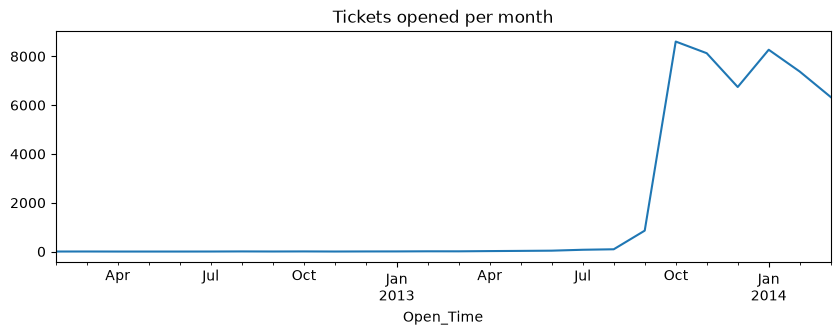

count      26.0
mean     1793.0
std      3260.0
min         0.0
25%         2.0
50%        10.0
75%       666.0
max      8606.0
dtype: float64


In [4]:
monthly = df.set_index("Open_Time").resample("MS").size()
monthly.plot(figsize=(10, 3), title="Tickets opened per month")
plt.show()
print(monthly.describe().round(0))

In [5]:
for c in ["CI_Cat", "Category", "Closure_Code"]:
    print(df[c].value_counts().head(8), "\n")

CI_Cat
application       32900
subapplication     7782
computer           3643
storage             703
hardware            442
software            333
database            214
displaydevice       212
Name: count, dtype: int64 

Category
incident                   37748
request for information     8846
complaint                     11
request for change             1
Name: count, dtype: int64 

Closure_Code
Other                           16470
Software                        13027
User error                       3554
No error - works as designed     3530
Hardware                         2999
Data                             2209
Unknown                          1590
Operator error                   1539
Name: count, dtype: int64 



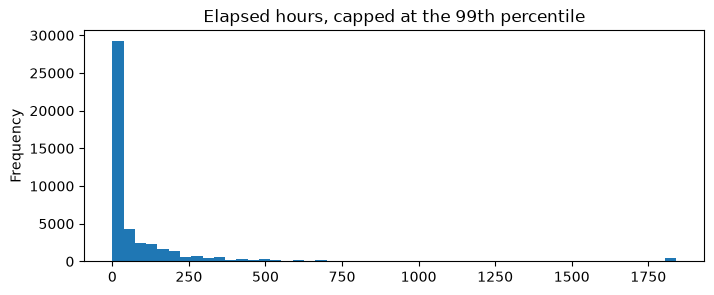

In [6]:
cap = df["Elapsed_hrs"].quantile(0.99)
df["Elapsed_hrs"].clip(upper=cap).plot.hist(bins=50, figsize=(8, 3), title="Elapsed hours, capped at the 99th percentile")
plt.show()

In [7]:
closed = df.set_index("Close_Time").resample("MS").size()
both = pd.DataFrame({"opened": monthly, "closed": closed}).fillna(0).astype(int)
print(both.loc["2013-07":])
print("Share opened Oct 2013 or later:", round((df["Open_Time"] >= "2013-10-01").mean() * 100, 1), "%")
print("Share closed Oct 2013 or later:", round((df["Close_Time"] >= "2013-10-01").mean() * 100, 1), "%")
print("Close_Time range:", df["Close_Time"].min().date(), "to", df["Close_Time"].max().date())

            opened  closed
2013-07-01      73       0
2013-08-01      93       0
2013-09-01     857       0
2013-10-01    8606    8544
2013-11-01    8128    8052
2013-12-01    6743    7013
2014-01-01    8270    8210
2014-02-01    7377    7542
2014-03-01    6332    7245
Share opened Oct 2013 or later: 97.5 %
Share closed Oct 2013 or later: 100.0 %
Close_Time range: 2013-10-01 to 2014-03-31


In [8]:
tot = lab.set_index("Open_Time").resample("MS").size()
hi = lab[lab["Priority"].isin([1, 2])].set_index("Open_Time").resample("MS").size()
print(pd.DataFrame({"labelled": tot, "high": hi}).fillna(0).astype(int).loc["2013-09":])

            labelled  high
Open_Time                 
2013-09-01       831     1
2013-10-01      8344   178
2013-11-01      7901   133
2013-12-01      6551   130
2014-01-01      8049   100
2014-02-01      7154    79
2014-03-01      6113    79


1. The 1,150 tickets opened before October are the backlog still open on 1 Oct (Sep 857, Aug 93, Jul 73, about 127 earlier). They are in the file only because they were slow, which is survivorship bias. High-priority tickets get fixed fast, so they almost never appear there. By my arithmetic, that is 1 High in 1,114 labelled (0.09%), against 699 in 44,112 (1.58%) from October on. Cell 8 checks this. Any feature that reveals “opened before October” would let a model learn “old means low priority”, which is an artifact.
2. Track 2 has 182 days of data. Quarterly forecasting is 2 data points and annual is none, so the brief’s quarterly and annual forecasts can’t be done. Daily or weekly forecasting works, with about 26 weeks and no yearly seasonality. Report this limit rather than working around it.
3. The High rate drifts down. A threshold tuned on October will over-alert in March.
4. Test sets are small. With 79 High cases in one month, recall is uncertain by roughly ±11 points. With 158 cases it is about ±8.

1. Modelling window: Open_Time on or after 2013-10-01. That is 45,456 rows, 44,112 labelled, 699 High. Earlier tickets stay in EDA and in one sensitivity check.
2. Track 1 split: train and tune on Oct to Jan with an expanding window (TimeSeriesSplit). That is 30,845 labelled and 541 High. Use Feb to Mar as the final test (13,267 labelled, 158 High) and touch it once. This replaces my earlier suggestion of a March-only test.
3. Track 2: daily or weekly counts only,

## confirms the survivorship effect

In [9]:
pre = lab[lab["Open_Time"] < "2013-10-01"]
win = lab[lab["Open_Time"] >= "2013-10-01"]
for name, part in [("Opened before Oct 2013", pre), ("Opened Oct 2013 onward", win)]:
    hi = part["Priority"].isin([1, 2]).sum()
    print(f"{name}: labelled {len(part)}, High {hi}, rate {hi / len(part) * 100:.2f}%")

Opened before Oct 2013: labelled 1114, High 1, rate 0.09%
Opened Oct 2013 onward: labelled 44112, High 699, rate 1.58%


## Tickets opened before Oct 2013 are rarely High priority


checks whether late March is cut off. Tickets opened in late March and still open on 31 March are missing from the file. Your opened-versus-closed drop in March (-14% against -4% in closed) hints at it but doesn’t prove it:

In [10]:
w = df[df["Open_Time"] >= "2013-10-01"]
wk = w.groupby(w["Open_Time"].dt.to_period("W")).agg(
    opened=("Incident_ID", "size"),
    median_elapsed_hrs=("Elapsed_hrs", "median"),
)
print(wk.round(1).tail(8))

                       opened  median_elapsed_hrs
Open_Time                                        
2014-02-10/2014-02-16    1749                18.0
2014-02-17/2014-02-23    1867                15.9
2014-02-24/2014-03-02    1656                 7.6
2014-03-03/2014-03-09    1540                16.0
2014-03-10/2014-03-16    1627                11.0
2014-03-17/2014-03-23    1514                 6.0
2014-03-24/2014-03-30    1421                 3.9
2014-03-31/2014-04-06     217                 1.8


In [11]:
print(df.loc[df["Status"] != "Closed", ["Open_Time", "Close_Time"]].agg(["min", "max"]))

              Open_Time          Close_Time
min 2013-10-08 13:10:00 2013-10-09 08:55:00
max 2013-10-28 15:03:00 2013-10-29 17:01:00


## monthly chart: marked the window start and labelled the axes

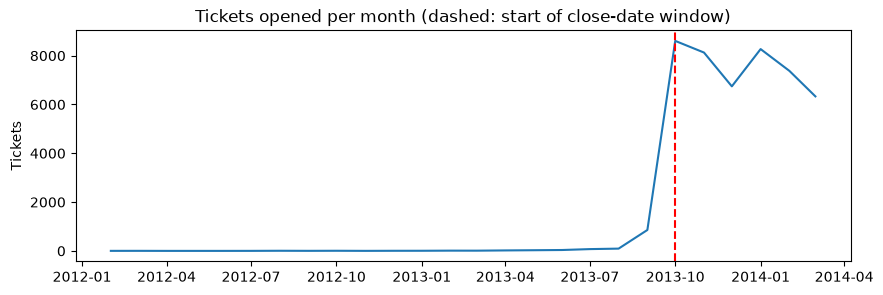

In [12]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(monthly.index, monthly.values)
ax.axvline(pd.Timestamp("2013-10-01"), color="red", linestyle="--")
ax.set_title("Tickets opened per month (dashed: start of close-date window)")
ax.set_ylabel("Tickets")
plt.show()

## Diagnostic cell to run next (aggregates only)

How to read it:

1. If p90_hrs and share_over_72h stay flat for weeks and then drop, censoring is confirmed, and the first week of the drop sets the cut-off.
2. If High tickets have a much lower median elapsed time than the rest, the High-rate inflation is plausible.
3. The weekly High counts show the rate drifting in the last weeks.

In [13]:
w = df[df["Open_Time"] >= "2013-10-01"].copy()
w["week"] = w["Open_Time"].dt.to_period("W")

tail = w.groupby("week").agg(
    opened=("Incident_ID", "size"),
    median_hrs=("Elapsed_hrs", "median"),
    p90_hrs=("Elapsed_hrs", lambda s: s.quantile(0.9)),
    share_over_72h=("Elapsed_hrs", lambda s: (s > 72).mean() * 100),
)
print(tail.round(1).tail(10))

lab_w = w[w["Priority"].notna()].copy()
lab_w["high"] = lab_w["Priority"].isin([1, 2])
print(lab_w.groupby("week")["high"].agg(["size", "sum"]).tail(10))
print(lab_w.groupby("high")["Elapsed_hrs"].median().round(1))

                       opened  median_hrs  p90_hrs  share_over_72h
week                                                              
2014-01-27/2014-02-02    2098         7.7    216.1            24.0
2014-02-03/2014-02-09    2111        16.8    215.2            26.4
2014-02-10/2014-02-16    1749        18.0    220.8            27.4
2014-02-17/2014-02-23    1867        15.9    205.2            26.7
2014-02-24/2014-03-02    1656         7.6    190.9            23.8
2014-03-03/2014-03-09    1540        16.0    174.5            26.4
2014-03-10/2014-03-16    1627        11.0    170.6            24.2
2014-03-17/2014-03-23    1514         6.0    140.9            19.2
2014-03-24/2014-03-30    1421         3.9     71.4             9.9
2014-03-31/2014-04-06     217         1.8      4.8             0.0
                       size  sum
week                            
2014-01-27/2014-02-02  2036   25
2014-02-03/2014-02-09  2059   25
2014-02-10/2014-02-16  1698   21
2014-02-17/2014-02-23  1799   1

1. Censoring is confirmed. The share over 72h sits at 24 to 27% for seven weeks, then falls to 19.2%, 9.9% and 0.0%. Part of the end drop is built in: a ticket opened on 29 or 30 March cannot show more than 72 hours when the data stops on 31 March. The 19.2% in the week of 17 March is the first week that is clearly off the plateau, and the p90 starts sliding a little earlier, from the week of 3 March.
2. The High rate points the way we expected, but only weakly. The seven plateau weeks average 1.14% (140 High of 12,259 labelled). The week of 24 March is 1.68%, which is 23 cases against about 16 expected. By my rough estimate that is about a 1-in-20 chance without any inflation, so it is suggestive, not conclusive.
3. The mechanism is credible. High tickets close much faster: median 3.8 hours against 18.1 for the rest. Late-March tickets still open on 31 March are mostly slow ones, so the missing ones are mostly not High, which pushes the High rate up.

Decision : 
1. Rows: 45,456 opened from October onward, minus 3,152 opened from 17 March, leaves about 42,304.
2. Track 1: train and tune on October to January (30,845 labelled, 541 High, 1.75%). Test on 1 February to 16 March (about 10,229 labelled, 115 High, 1.12%). That is 43 High fewer than my earlier plan, so recall on the test set is uncertain by roughly ±9 points. Say that in the write-up.
3. Drift: the High rate falls from 1.75% in training to about 1.12% in the test period, so a threshold tuned on October to January will over-alert on the test set.
4. Track 2: the same window gives about 167 daily points. That’s enough for daily or weekly forecasts and nothing longer.

In [14]:
start = pd.Timestamp("2013-10-01")
cut = pd.Timestamp("2014-03-17")
mw = df[(df["Open_Time"] >= start) & (df["Open_Time"] < cut)]
print("Modelling window rows:", len(mw), "| opened from cut-off:", int((df["Open_Time"] >= cut).sum()))

lab_m = mw[mw["Priority"].notna()]
for name, a, b in [("Train/tune Oct-Jan", "2013-10-01", "2014-02-01"),
                   ("Test Feb to 16 Mar", "2014-02-01", "2014-03-17")]:
    part = lab_m[(lab_m["Open_Time"] >= a) & (lab_m["Open_Time"] < b)]
    hi = part["Priority"].isin([1, 2]).sum()
    print(f"{name}: labelled {len(part)}, High {hi}, rate {hi / len(part) * 100:.2f}%")

Modelling window rows: 42304 | opened from cut-off: 3152
Train/tune Oct-Jan: labelled 30845, High 541, rate 1.75%
Test Feb to 16 Mar: labelled 10229, High 115, rate 1.12%
